# **Projeto MPBA | Mestrado Business Intelligence & Analytics**

## **Kaggle Competitions:** *Titanic - Machine Learning from Disaster*
https://www.kaggle.com/competitions/titanic

### **Projeto desenvolvido por:**
- João Vasques, nº2250055
- Rui Filipe Parada, nº2211025

---

### **Contextualização do projeto**
O presente projeto baseia‑se na competição “Titanic: Machine Learning from Disaster”, disponibilizada na plataforma Kaggle. O objetivo é aplicar técnicas de Machine Learning para prever se determinado passageiro sobreviveu ao naufrágio do Titanic em 1912 com base em características individuais. Nesta competição, recebemos três conjuntos de dados: um *train.csv*, que contém tanto as features quanto a informação de sobrevivência (`'Survived'`), um *test.csv*, que contém apenas as features, e um *gender_submission.csv* que consiste num exemplo de como os dados devem ser apresentados para a submissão dos resultados no kaggle, neste exemplo assume-se que apenas passageiros do sexo feminino sobrevivem.

| __*Feature*__ | __Descrição__ |
| :--- | :--- |
| __PassengerId__ | Identificador único atribuído a cada passageiro. |
| __Survived__ | Variável target - indica se o passageiro sobreviveu (1) ou não (0) ao naufrágio. |
| __Pclass__ | Classe do bilhete do passageiro (1, 2 ou 3). |
| __Name__ | Nome completo do passageiro. |
| __Sex__ | Género do passageiro. |
| __Age__ | Idade do passageiro em anos. |
| __SibSp__ | Número de irmãos/cônjuges a bordo. |
| __Parch__ | Número de pais/filhos a bordo. |
| __Ticket__ | Identificador do bilhete. |
| __Fare__ | Preço pago pelo bilhete. |
| __Cabin__ | Número da cabine. |
| __Embarked__ | Porto de embarque do passageiro: C (Cherbourg), Q (Queenstown) ou S (Southampton). |



---

### **Resumo**

Neste projeto, analisamos o conjunto de dados do Titanic com o objetivo de prever a sobrevivência dos passageiros de `df_test`. Começamos por uma análise exploratória, separada em análises base e em análises específicas das features, e tratamento dos dados, incluindo a gestão de valores nulos e a criação de novas features relevantes, `'Family_Size'`, `'Title'`, `'Age_Range'` e `'Fare_Intervals'`.

Em seguida, aplicamos diversos algoritmos de classificação (KNN, Logistic Regression, SVM, Decision Tree, Random Forest, Gradient Boosting, XGBoost e LightGBM), utilizando GridSearchCV para otimização de hiperparâmetros e técnicas de balanceamento de classes para lidar com o desbalanceamento do target (`'Survived'`). Avaliamos cada modelo com métricas de precision, recall, F1-score e accuracy, além de analisar as matrizes de confusão para compreender erros específicos de classificação.

Consolidámos os resultados numa tabela comparativa, o que permitiu identificar os modelos mais robustos e compreender o impacto das variáveis no respetivo desempenho preditivo. Após a submissão, verificámos que o modelo obteve uma classificação bastante elevada no ranking, reforçando a sua capacidade preditiva.
De forma global, este trabalho evidencia a aplicação sistemática de análise exploratória, data preprocessing, feature engineering e técnicas de predictive modeling em problemas de classificação binária.


# **1. Imports**

In [ ]:
from google.colab import files
import io

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

import warnings
warnings.filterwarnings('ignore')

# **2. Data Upload**

In [ ]:
uploaded = files.upload()
df_train = pd.read_csv(io.BytesIO(uploaded['train.csv']), sep=',')
df_test = pd.read_csv(io.BytesIO(uploaded['test.csv']), sep=',')

Saving test.csv to test.csv
Saving train.csv to train.csv


# **3. Data Analysis**

### **3.1) Análise visual dos datasets**

In [ ]:
### ---1. VISUALIZAÇÃO DE df_train--- ###

df_train.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [ ]:
### ---2. VISUALIZAÇÃO DE df_test--- ###

df_test.head(10)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
5,897,3,"Svensson, Mr. Johan Cervin",male,14.0,0,0,7538,9.2250,NaN,S
6,898,3,"Connolly, Miss. Kate",female,30.0,0,0,330972,7.6292,NaN,Q
7,899,2,"Caldwell, Mr. Albert Francis",male,26.0,1,1,248738,29.0000,NaN,S
8,900,3,"Abrahim, Mrs. Joseph (Sophie Halaut Easu)",female,18.0,0,0,2657,7.2292,NaN,C
9,901,3,"Davies, Mr. John Samuel",male,21.0,2,0,A/4 48871,24.1500,NaN,S


### **3.2) Análise Inicial**

In [ ]:
### ---1. ANÁLISE DOS DATASETS ORIGINAIS--- ###

print("----- ANÁLISE DOS DATASETS ORIGINAIS -----\n")

# Forma do dataset
print("----- Forma do dataset -----")
print(f"df_train shape:   {df_train.shape}")
print(f"df_test shape:    {df_test.shape}\n")

# Tipos de dados
print("----- Tipo de dados do dataset -----")
print("df_train dtypes:")
print(df_train.dtypes, "\n")

print("df_test dtypes:")
print(df_test.dtypes, "\n")

# Estatísticas descritivas
print("----- Dados descritivos do dataset -----")
print("df_train describe:")
print(df_train.describe(), "\n")

print("df_test describe:")
print(df_test.describe(), "\n")

# Duplicados
print("----- Duplicados do dataset -----")
print(f"df_train duplicados:   {df_train.duplicated().sum()}")
print(f"df_test duplicados:    {df_test.duplicated().sum()}\n")

# Nulos por coluna
print("----- Nulos por coluna -----")
print("df_train:")
print(df_train.isnull().sum(), "\n")

print("df_test:")
print(df_test.isnull().sum(), "\n")

# Total de nulos
print("----- Total de nulos -----")
print(f"df_train total de nulos:   {df_train.isnull().sum().sum()}")
print(f"df_test total de nulos:    {df_test.isnull().sum().sum()}")


----- ANÁLISE DOS DATASETS ORIGINAIS -----

----- Forma do dataset -----
df_train shape:   (891, 12)
df_test shape:    (418, 11)

----- Tipo de dados do dataset -----
df_train dtypes:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object 

df_test dtypes:
PassengerId      int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object 

----- Dados descritivos do dataset -----
df_train describe:
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308

- **Forma do dataset:** O dataset de treino contém 891 linhas e 12 colunas, o dataset de teste possui 418 linhas e 11 colunas, enquanto o dataset de resultados apresenta 418 linhas e 2 colunas. Os tamanhos do `df_test` e `df_resultados` são compatíveis, mas precisamos de ter em atenção se se mantém compatíveis após o tratamento de dados.

- **Tipos de dados:** As colunas categóricas, como `'Sex'`, `'Name'`, `'Ticket'`, `'Cabin'` e `'Embarked'`, estão corretamente como object, enquanto `'PassengerId'`, `'Survived'`, `'Pclass'`, `'SibSp'` e `'Parch'` são inteiros, e `'Age'` e `'Fare'` estão como float. Não pensamos ser necessário fazer conversões neste momento.

- **Estatísticas descritivas:** A idade média dos passageiros do treino é 29,7 anos, com mínimo de 0,42 e máximo de 80 anos, enquanto a tarifa média é 32,2, mas com grande desvio padrão (49,7), o que nos indica que há valores extremos que devem ser observados. O número médio de irmãos/cônjuges a bordo (`'SibSp'`) é 0,52, e de pais/filhos (`'Parch'`) é 0,38. O `df_test` apresenta padrões similares.

- **Duplicados:** Não existem *samples* duplicadas em nenhum dos três datasets.

- **Valores nulos:** O `df_train` contém 866 valores nulos, distribuídos pelas colunas `'Age'` (177), `'Cabin'` (687) e `'Embarked'` (2). O `df_test` apresenta 414 NaN, concentrados em `'Age'` (86), `'Cabin'` (327) e `'Fare'` (1). O `df_results` não contém *missing values*. No bloco 4. Feature Engineering teremos de tratar estas features.

In [ ]:
### ---2. SEPARAÇÃO DE COLUNAS NUMÉRICAS E CATEGÓRICAS--- ###

numerical_cols = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
categorical_cols = ['Sex', 'Embarked']

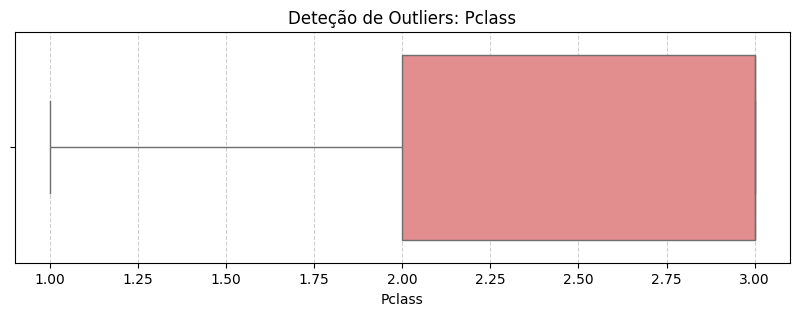

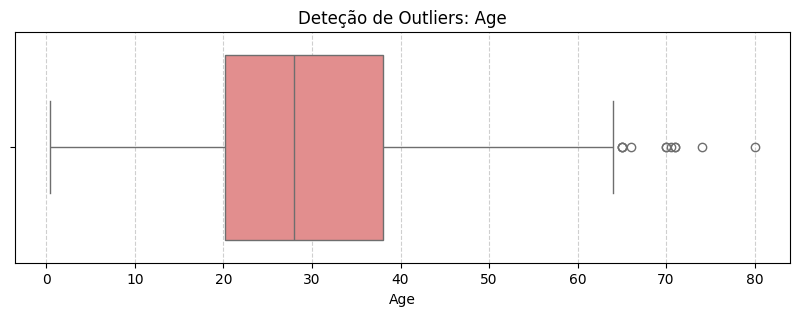

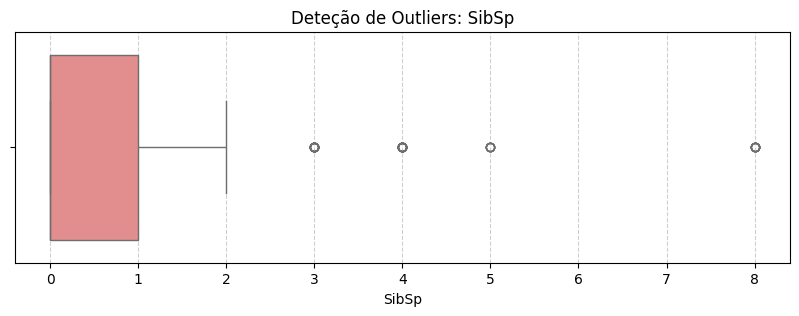

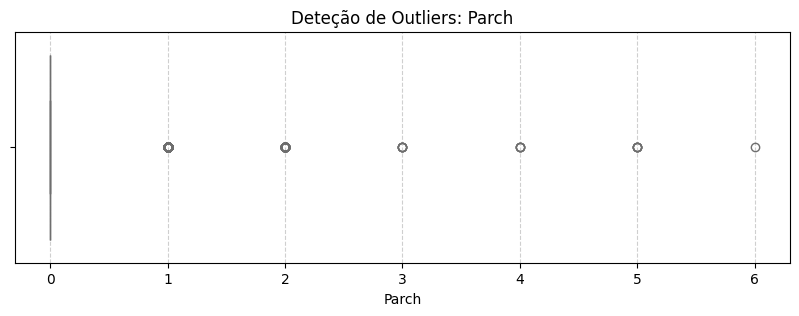

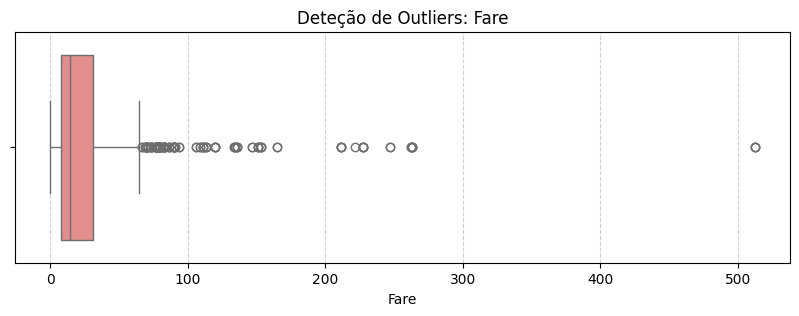

In [ ]:
### ---3. DETEÇÃO DE OUTLIERS: BOXPLOTS--- ###

for col in numerical_cols:
    plt.figure(figsize=(10, 3))
    sns.boxplot(x=df_train[col], color='lightcoral')
    plt.title(f'Deteção de Outliers: {col}')
    plt.grid(axis='x', linestyle='--', alpha=0.6)
    plt.show()

In [ ]:
### ---4. DETEÇÃO DE OUTLIERS: MÉTRICAS--- ###

for col in numerical_cols:
    Q1 = df_train[col].quantile(0.25)
    Q3 = df_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 3 * IQR
    upper_limit = Q3 + 3 * IQR

    outliers = df_train[
        (df_train[col] < lower_limit) | (df_train[col] > upper_limit)
    ]

    print(f"\n--- {col} ---")
    print("Número de outliers:", outliers.shape[0])
    print("Limites IQR:")
    print("Lower:", lower_limit)
    print("Upper:", upper_limit)

    if outliers.shape[0] > 0:
        print("Min / Max dos outliers:")
        print(outliers[col].agg(["min", "max"]))


--- Pclass ---
Número de outliers: 0
Limites IQR:
Lower: -1.0
Upper: 6.0

--- Age ---
Número de outliers: 0
Limites IQR:
Lower: -33.5
Upper: 91.625

--- SibSp ---
Número de outliers: 12
Limites IQR:
Lower: -3.0
Upper: 4.0
Min / Max dos outliers:
min    5
max    8
Name: SibSp, dtype: int64

--- Parch ---
Número de outliers: 213
Limites IQR:
Lower: 0.0
Upper: 0.0
Min / Max dos outliers:
min    1
max    6
Name: Parch, dtype: int64

--- Fare ---
Número de outliers: 53
Limites IQR:
Lower: -61.358399999999996
Upper: 100.2688
Min / Max dos outliers:
min    106.4250
max    512.3292
Name: Fare, dtype: float64


Analisando as colunas numéricas (`numericals_cols`) do `df_train`, verificamos que não existem *outliers* para `'Pclass'` e `'Age'`, o que indica que as cabines e a idade dos passageiros estão dentro de limites esperados.

Para `'SibSp'` (número de irmãos/cônjuges a bordo), identificamos 12 *outliers*, com valores entre 5 e 8, acima do limite superior definido pelo IQR. Estes passageiros representam situações atípicas de famílias muito grandes a bordo.

Na coluna `'Parch'` (número de pais/filhos a bordo), surgem 213 *outliers* com valores entre 1 e 6, considerando que o limite superior pelo IQR é 0. Isso indica que a maior parte dos passageiros viajava sem pais ou filhos, mas há grupos familiares significativos que se destacam como casos extremos.

Para `'Fare'` (preço), encontramos 53 *outliers* com valores entre 106,43 e 512,33, acima do limite superior de 100,27. Estes correspondem a passageiros que pagaram tarifas muito altas, provavelmente associados a classes superiores ou cabines especiais.

Em resumo, as colunas que requerem mais atenção em termos de *outliers* são `'SibSp'`, `'Parch'` e `'Fare'`.
De modo a sermos mais permissivos, decidimos utilizar 3 ao invés de 1.5 no cálculos dos limites:
$$lower limit = Q1 - 3 * IQR$$
$$upper limit = Q3 + 3 * IQR$$
Mesmo assim, dada tal permissibilidade, não nos parece necessário tratar estes dados, pois são valores plausíveis dentro do contexto do dataset, sendo justificáveis pela natureza do que cada feature representa.

### **3.3) Análise Univariada**

Prosseguindo para um estudo univariado, coluna a coluna, separamos a análise das variáveis numéricas da análise das variáveis categóricas.

**Variáveis Numéricas:**

- Análise descritiva com a contagem dos valores únicos de cada feature numérica;

- Análise gráfica com o recurso a Histogramas (com kde), o que nos ajuda a perceber a distribuição dos valores.

**Variáveis Categóricas:**

- Análise descritiva com a contagem dos valores únicos de cada feature categórica;

- Análsie gráfica com um Barplot que mostra as 20 labels mais frequentes por feature.

### **3.3.1) Variáveis Numéricas**


------------------------------------Contagem de valores únicos para Variáveis Numéricas:------------------------------------

Pclass
3    491
1    216
2    184
Name: count, dtype: int64
... (3 valores únicos no total)

Age
24.00    30
22.00    27
18.00    26
28.00    25
30.00    25
         ..
24.50     1
0.67      1
0.42      1
34.50     1
74.00     1
Name: count, Length: 88, dtype: int64
... (88 valores únicos no total)

SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64
... (7 valores únicos no total)

Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64
... (7 valores únicos no total)

Fare
8.0500     43
13.0000    42
7.8958     38
7.7500     34
26.0000    31
           ..
13.8583     1
50.4958     1
5.0000      1
9.8458      1
10.5167     1
Name: count, Length: 248, dtype: int64
... (248 valores únicos no total)


------------------------------------Gráficos para variáveis numéricas (Histograma)

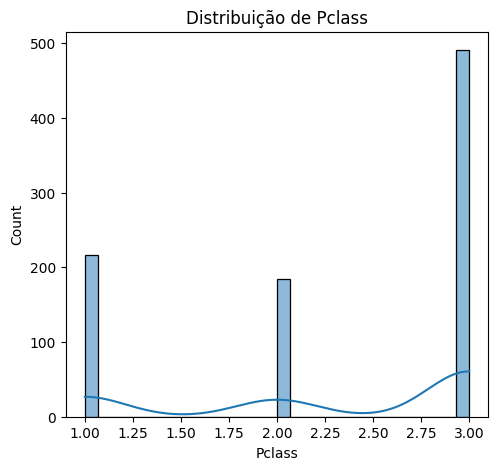

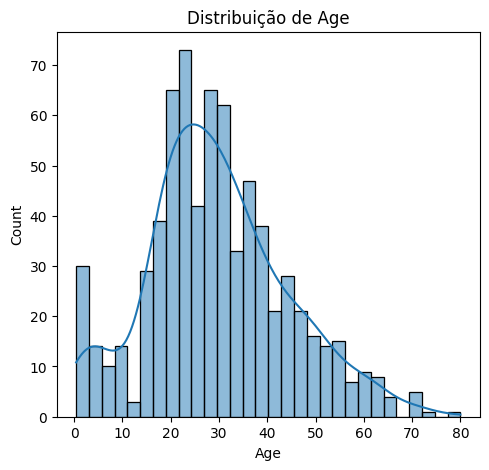

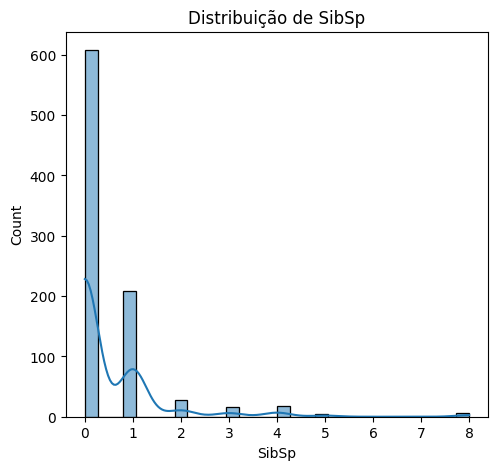

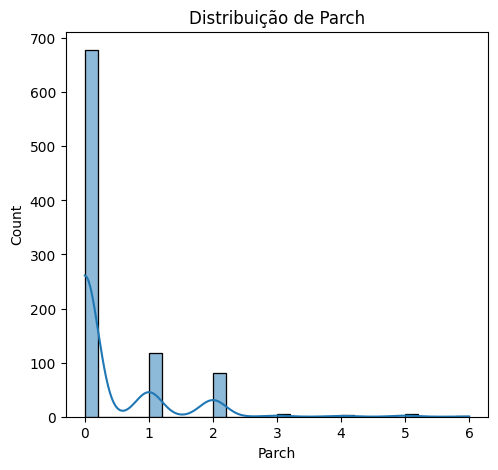

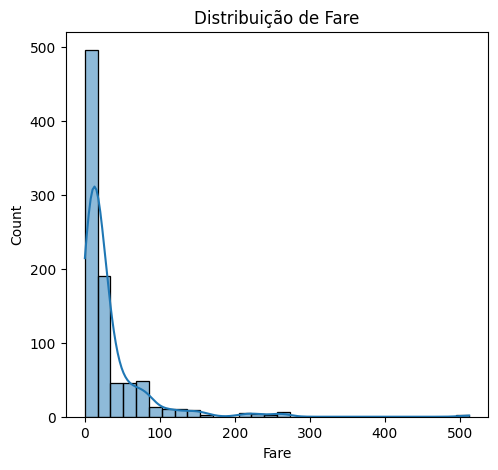

In [ ]:
### ---1.1. ESTATÍSTICAS DESCRITIVAS--- ###

print("\n------------------------------------Contagem de valores únicos para Variáveis Numéricas:------------------------------------\n")
for col in numerical_cols:
    value_counts = df_train[col].value_counts()
    print(value_counts)
    print(f"... ({len(value_counts)} valores únicos no total)\n")


### ---1.2. VISUALIZAÇÕES GRÁFICAS--- ###

print("\n------------------------------------Gráficos para variáveis numéricas (Histograma):------------------------------------\n")
for col in numerical_cols:
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    sns.histplot(df_train[col], kde=True, bins=30)
    plt.title(f'Distribuição de {col}')

    plt.show()

### **3.3.2) Variáveis Categóricas**


------------------------------------Contagem de valores únicos para Variáveis Categóricas:------------------------------------

Sex
male      577
female    314
Name: count, dtype: int64
... (2 valores únicos no total)

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64
... (3 valores únicos no total)


------------------------------------Gráficos para variáveis categóricas (Barplot):------------------------------------



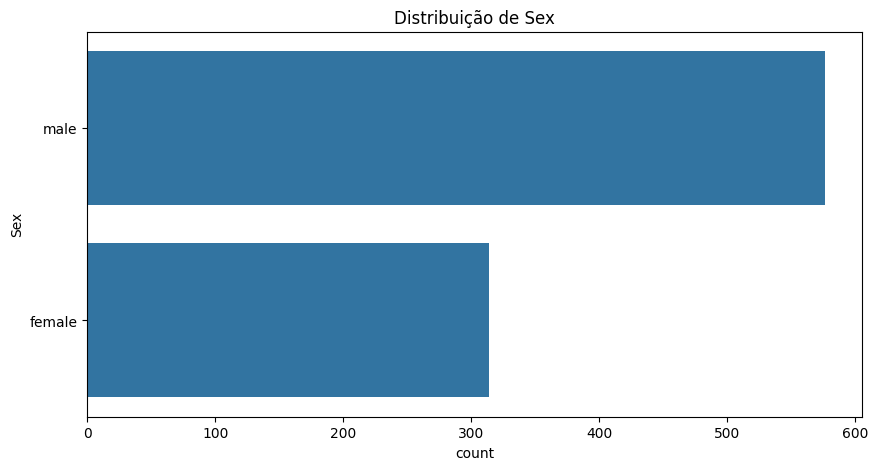

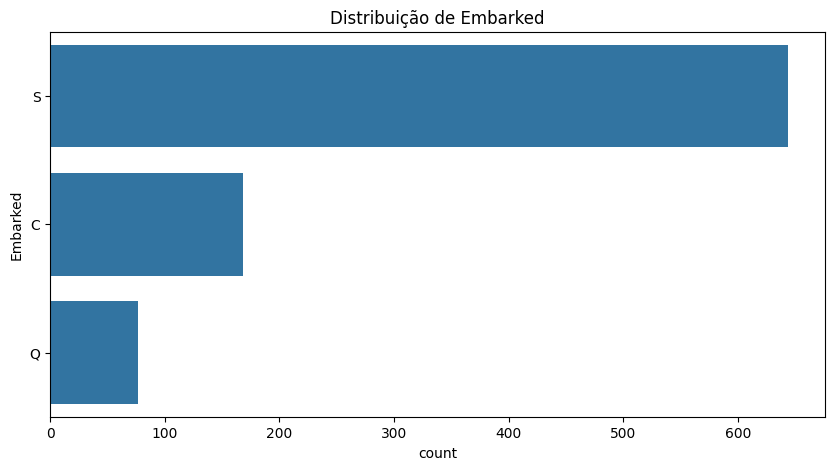

In [ ]:
### ---2.1. ESTATÍSTICAS DESCRITIVAS--- ###

print("\n------------------------------------Contagem de valores únicos para Variáveis Categóricas:------------------------------------\n")
for col in categorical_cols:
    value_counts = df_train[col].value_counts()
    print(value_counts)
    print(f"... ({len(value_counts)} valores únicos no total)\n")


### ---2.2. VISUALIZAÇÕES GRÁFICAS--- ###

print("\n------------------------------------Gráficos para variáveis categóricas (Barplot):------------------------------------\n")
for col in categorical_cols:
    plt.figure(figsize=(10, 5))
    sns.countplot(y=df_train[col], order=df_train[col].value_counts().index)
    plt.title(f'Distribuição de {col}')

    plt.show()

### **3.4) Análises específicas**

In [ ]:
### ---1. ANÁLISES ESPECÍFICAS--- ###

# -> 1.1.) 'Sex' - Percentagem de sobreviventes por sexo
print("\n------------------------------------Percentagem de sobreviventes por sexo------------------------------------")

survival_male = df_train[df_train['Sex'] == 'male']['Survived'].mean() * 100
print(f"Percentagem de homens que sobreviveram: {survival_male:.2f}%")

survival_female = df_train[df_train['Sex'] == 'female']['Survived'].mean() * 100
print(f"Percentagem de mulheres que sobreviveram: {survival_female:.2f}%")



# -> 1.2.) 'Age' - Percentagem de sobreviventes por idade (separada em faixa etária)
print("\n------------------------------------Percentagem de sobreviventes por idade (separada em faixa etária)------------------------------------")

bins = [0, 18, 44, 64, 120]
labels = ['0-18', '19-44', '45-64', '65+']

for i in range(len(bins) - 1):  # Loop pelos bins
    lower = bins[i]
    upper = bins[i+1]
    label = labels[i]

    mask = (df_train['Age'] >= lower) & (df_train['Age'] < upper)
    pct = df_train.loc[mask, 'Survived'].mean() * 100

    print(f"{label}: {pct:.2f}%")



# -> 1.3.) 'Sex' e 'Age' - Percentagem de sobreviventes por sexo e idade (separada em faixa etária)
print("\n------------------------------------Percentagem de sobreviventes por sexo e idade (separada em faixa etária)------------------------------------")

bins = [0, 18, 44, 64, 120]
labels = ['0-18', '19-44', '45-64', '65+']

for i in range(len(bins) - 1):
    lower = bins[i]
    upper = bins[i+1]
    label = labels[i]

    mask_bin = (df_train['Age'] >= lower) & (df_train['Age'] < upper)

    male_mask = mask_bin & (df_train['Sex'] == 'male')
    female_mask = mask_bin & (df_train['Sex'] == 'female')

    pct_male = df_train.loc[male_mask, 'Survived'].mean() * 100
    pct_female = df_train.loc[female_mask, 'Survived'].mean() * 100

    print(f"{label}: Homens = {pct_male:.2f}%, Mulheres = {pct_female:.2f}%")



# -> 1.4.) 'Pclass' - Percentagem de sobreviventes por classe
print("\n------------------------------------Percentagem de sobreviventes por classe------------------------------------")

survival_by_class = df_train.groupby('Pclass')['Survived'].mean() * 100

for cls, pct in survival_by_class.items():
    print(f"Classe {cls}: {pct:.2f}%")



# -> 1.5.) 'Cabin' e 'Pclass' - Distribuição de letras de cabine por classe (em percentagem)   |   Tentativa de tratamento da coluna 'Cabin'
print("\n------------------------------------Distribuição de letras de cabine por classe (em percentagem)------------------------------------")

cabin_letter = df_train['Cabin'].dropna().apply(lambda x: x[0]) # Coluna temporária com a letra da cabine

temp = pd.DataFrame({
    'Pclass': df_train.loc[cabin_letter.index, 'Pclass'],
    'CabinLetter': cabin_letter
}) # DataFrame temporário apenas com Pclass e CabinLetter

for cls in sorted(temp['Pclass'].unique()):
    subset = temp[temp['Pclass'] == cls]
    total = len(subset)

    print(f"Classe {cls}:")

    pct = (subset['CabinLetter'].value_counts(normalize=True) * 100).sort_index()

    for letter, value in pct.items():
        print(f"  {letter}: {value:.2f}%")



# -> 1.6.) 'Cabin' e 'Pclass' - Distribuição da classe onde a cabine é nula (em percentagem)   |   Tentativa de tratamento da coluna 'Cabin'
print("\n------------------------------------Distribuição da classe onde a cabine é nula (em percentagem)------------------------------------")

pclass_dist_null_cabin = df_train[df_train['Cabin'].isna()]['Pclass'].value_counts(normalize=True) * 100

for cls, pct in pclass_dist_null_cabin.items():
    print(f"Classe {cls}: {pct:.2f}%")



# -> 1.7.) 'Cabin' - Total de sobreviventes por cabine (letra inicial)   |   Tentativa de tratamento da coluna 'Cabin'
print("\n------------------------------------Total de sobreviventes por cabine (letra inicial)------------------------------------\n")

cabin_letter = df_train['Cabin'].str[0]

tabela_cabin = pd.crosstab(df_train['Survived'],cabin_letter,dropna=False)

print(tabela_cabin)



# -> 1.8.) 'Parch' - Percentagem de sobrevivência por 'Parch' - número de filhos e pais a bordo (com média da idade)
print("\n------------------------------------Percentagem de sobrevivência por 'Parch' - número de filhos e pais a bordo (com média da idade)------------------------------------\n")

tabela_parch = pd.DataFrame({
    'Número Passageiros': df_train['Parch'].value_counts().sort_index(),
    'Taxa Sobrevivencia (%)': (df_train.groupby('Parch')['Survived'].mean() * 100).round(2),
    'Média Idade': df_train.groupby('Parch')['Age'].mean().round(2)
})

print(tabela_parch)



# -> 1.9.) 'SibSp' - Percentagem de sobrevivência por 'SibSp' - número de irmãos e cônjugue a bordo (com média da idade)
print("\n------------------------------------Percentagem de sobrevivência por 'SibSp' - número de filhos e pais a bordo (com média da idade)------------------------------------\n")

tabela_sibsp = pd.DataFrame({
    'Némero Passageiros': df_train['SibSp'].value_counts().sort_index(),
    'Taxa Sobrevivencia (%)': (df_train.groupby('SibSp')['Survived'].mean() * 100).round(2),
    'Média Idade': df_train.groupby('SibSp')['Age'].mean().round(2)
})

print(tabela_sibsp)



# -> 1.10.) 'Pclass' e 'Embarked' - Total e Percentagem de passageiros por classe por cidade
print("\n------------------------------------Total e Percentagem de passageiros por classe por cidade------------------------------------\n")

tabela_contagem = pd.crosstab(df_train['Pclass'], df_train['Embarked'])
print(tabela_contagem)

tabela_pct_por_porto = pd.crosstab(
    df_train['Pclass'],
    df_train['Embarked'],
    normalize='columns'
) * 100

print(tabela_pct_por_porto.round(2))



# -> 1.11.) 'Ticket' - Total de bilhetes duplicados
print("\n------------------------------------Total de bilhetes duplicados------------------------------------")

duplicated_tickets = df_train[df_train['Ticket'].duplicated(keep=False)]
total_passengers_ticket = len(duplicated_tickets)
total_tickets_unicos = duplicated_tickets['Ticket'].nunique()

print(f"Total de passageiros com tickets duplicados: {total_passengers_ticket}")
print(f"Total de tickets únicos duplicados: {total_tickets_unicos}")



# -> 1.12.) 'Fare', 'Pclass' e 'Embarked' - Média de preço por classe por cidade
print("\n------------------------------------Média de preço por classe por cidade------------------------------------\n")

fare_table = pd.pivot_table(
    df_train,
    values='Fare',
    index='Embarked',
    columns='Pclass',
    aggfunc='mean'
)

print(fare_table)



# -> 1.13.) 'Fare', 'Pclass' e 'Embarked' - Classe e Cidade do passageiro com Fare == Nan   |   Tentativa de tratamento da coluna 'Fare' (em df_test)
print("\n------------------------------------Classe e Cidade do passageiro com Fare == Nan------------------------------------\n")

print(df_test.loc[df_test['Fare'].isna(), ['PassengerId', 'Pclass', 'Embarked']])



# -> 1.14.) 'SibSp' e 'Parch' - Tamanho da família completa a bordo de cada passageiro
print("\n------------------------------------Tamanho da família completa a bordo de cada passageiro ------------------------------------")

family_var = df_train.copy()
family_var['Family_Size'] = family_var['SibSp'] + family_var['Parch'] + 1 # Nr irmãos e/ou côngugue + Nr filhos e/ou pais + 1 (o próprio passageiro)

surv_by_family = (
    family_var
    .groupby('Family_Size')['Survived']
    .mean()
    .reset_index()
    .rename(columns={'Family_Size': 'Family_Size', 'Survived': 'Survival_Rate'})
)

print(f"\n{surv_by_family}")



------------------------------------Percentagem de sobreviventes por sexo------------------------------------
Percentagem de homens que sobreviveram: 18.89%
Percentagem de mulheres que sobreviveram: 74.20%

------------------------------------Percentagem de sobreviventes por idade (separada em faixa etária)------------------------------------
0-18: 53.98%
19-44: 38.36%
45-64: 40.54%
65+: 7.69%

------------------------------------Percentagem de sobreviventes por sexo e idade (separada em faixa etária)------------------------------------
0-18: Homens = 39.66%, Mulheres = 69.09%
19-44: Homens = 17.74%, Mulheres = 76.65%
45-64: Homens = 19.44%, Mulheres = 79.49%
65+: Homens = 7.69%, Mulheres = nan%

------------------------------------Percentagem de sobreviventes por classe------------------------------------
Classe 1: 62.96%
Classe 2: 47.28%
Classe 3: 24.24%

------------------------------------Distribuição de letras de cabine por classe (em percentagem)---------------------------------

A análise detalhada do dataset do Titanic revela padrões claros de sobrevivência em função de sexo, idade, classe, família a bordo, cabine, porto de embarque e tarifa (preço do bilhete). Observa-se que o sexo é um fator determinante, com mulheres a apresentar uma taxa de sobrevivência significativamente maior (74,2%) em comparação com os homens (18,9%).
A idade também desempenha um papel relevante. Crianças e jovens até aos 18 anos apresentam a maior taxa de sobrevivência (53,98%), enquanto adultos entre 19–44 anos (38,36%) e 45–64 anos (40,54%) mostram valores mais moderados. Já os passageiros com 65 ou mais anos apresentam uma taxa bastante reduzida (7,69%).

Quando combinamos as duas *features* surgem padrões relevantes. Entre os 0-18 anos de idade sobrevivem 69% das mulheres e 39,7% dos homens, entre os grupos de idades de 19-44 e 45-65, como era esperado, verifica-se uma maior taxa de sobrevivência nas mulheres (76,7% e 79,5%, respetivamente) comparativamente aos homens (17,7% e 19,44%, respetivamente). Na faixa etária de 65+, apenas homens apresentam taxa de sobrevivência, sendo esta bastante baixa (7,69%). No caso das mulheres (nan%), podemos concluir que o *dataset* não inclui nenhum caso de uma mulher acima dos 65 anos.

A classe social apresenta forte correlação com a sobrevivência, onde passageiros da primeira classe têm taxa de 62,96%, seguidos pela segunda classe com 47,28% e terceira classe com 24,24%.

Relativamente à distribuição de cabines, podemos verificar que a análise da coluna cabine é complexa. A localização da cabine depende da letra inicial e do primeiro número que a segue, possibilitando a análise de taxa de sobrevivência relativa à localização do passageiro no barco na hora do acidente. No entanto, existem demasiados *missing values* (687) para tornar viável o uso da mesma.

O número de familiares a bordo também impacta a sobrevivência. Passageiros com pelo menos um pai ou filho (`'Parch'` 1–2) têm taxas de sobrevivência mais altas (50–55%), enquanto grandes grupos familiares apresentam risco maior. Um padrão semelhante é observado para irmãos e cônjuges (`'SibSp'`), onde presença de um familiar aumenta a chance de sobrevivência, mas grupos grandes (3 ou mais) reduzem significativamente essas chances.

O porto de embarque também se relaciona com a classe: passageiros da primeira classe estão concentrados nos portos C e S, enquanto a terceira classe é maioritária do porto S. A tarifa paga (`'Fare'`) segue o mesmo padrão, com valores médios mais altos para a primeira classe e portos C e Q, e mais baixos para a terceira classe e porto S, mostrando que a tarifa pode ser utilizada para associar status socioeconómicos aos passageiros. Há ainda um passageiro no conjunto de teste com `'Fare'` ausente, necessita de tratamento no Bloco 4 abaixo.

Por fim, existem tickets compartilhados: 344 passageiros viajam com tickets iguais a pelo menos outro passageiro. Existem no total 134 tickets únicos, indicando que grupos ou famílias viajaram juntos. Contudo, mais relevante que a análise de grupos com o mesmo ticket, é a análise do tamanho da família a bordo. Através da *feature* `'Family_Size'` (combinação das *features* `'Parch'` e `'SibSp'`) podemos comparar a taxa de sobrevivência dos passageiros que viajavam sozinhos com os que viajavam acompanhados por família, podendo afirmar que quem viaja acompanhado por família entre 3 e 4 elementos, apresenta uma taxa bastante superior de sobrevivência comparativamente aos restantes grupos.

Sintetizando, podemos concluir que a taxa de sobrevivência é influenciada principalmente pelo sexo e idade do passageiro em questão, beneficiando as mulheres e os jovens. De seguida, a classe também demonstra ser bastante relevante, refletindo desigualdades socioeconómicas na taxa de sobrevivência. Por fim, a estrutura familiar também desempenha um papel sublinhável, favorecendo famílias pequenas em detrimento de grupos numerosos e passageiros que viajavam sozinhos. Para futuras análises, pode ainda ser relevante explorar a *feature* `'Cabin'`, pois demonstra padrões consistentes relativos à taxa de sobrevivência, apesar da falta de dados. Tendo em conta que o acidente ocorreu em torno das 23:40 seria bastante provável que os passageiros se encontravassem próximos das suas cabines.

# **4. Feature Engineering**

In [ ]:
### ---1. CRIAÇÃO DE df_train_limpo E df_test_limpo--- ###

df_train_limpo = df_train.copy() # cópia criada para o tratamento de dados, preservando a estrutura do df original
df_test_limpo = df_test.copy() # cópia criada para o tratamento de dados, preservando a estrutura do df original

**Tratamento de Missing Values:**

- **`'Cabin'`**: dar drop à coluna.

Como referido anteriormente, especulamos que a coluna `'Cabin'`, se completa, poderia ter grande importância para a previsão, por representar os passageiros do navio em termos de localização. Como tal, ponderamos preencher os valores em falta de várias formas: através da coluna `'Pclass'`, atribuindo a letra da `'Cabin'` mais frequente à classe que dado passageiro pertence; através da coluna `'Ticket'`, tentando rastrear bilhetes com o mesmo número (para pasageiros que viajavam em grupo), identificando um elemento do grupo com a coluna `'Cabin'` preenchida e associando aos restantes elementos do grupo a mesma cabine.

Contudo, tendo em perspetiva que os NaN desta feature representam entre 77% e 78% de `df_train` e `df_test`, respetivamente, tomamos a decisão de não preencher os dados em falta, pois estaríamos a criar muitos dados irreais.

- **`'Age'`**: preencher com a mediana.

Dado o significativo volume de missing values nesta coluna, decidimos fazer imputação com base nos dados da própria coluna. Restava escolhermos entre moda, média ou mediana.

Foram consideradas três abordagens possíveis para imputação dos valores em falta:
1) **Moda**: Rejeitamos, pois a idade é uma variável quase contínua. A imputação pela moda cria picos artificiais e reduz a variabilidade dos dados, introduzindo ruído estatístico no modelo.

2) **Média**: Embora comum, a média é sensível a outliers (crianças muito novas e poucos idosos). Rejeitamos, pois a média pode deslocar o valor central e introduzir viés.

3) **Mediana** (opção escolhida):
   A mediana é robusta a outliers e preserva melhor a tendência central da
   distribuição original. Esta abordagem minimiza distorções e evita a
   introdução de estrutura artificial nos dados.

- **`'Embarked'`**: dar drop às duas linhas.

Ponderamos associar a classe dos passageiros (`'Pclass'`) à cidade de onde embarcaram (`'Embarked'`). Contudo, verificamos que os dois passageiros com valor em falta na coluna `'Embarked'` pertencem à 1ª Classe (`'Pclass'` == 1) e que, nesta classe, a distribuição de embarcados é muito semelhante entre Cherbourg (`'Embarked'` == 'C') e Southampton (`'Embarked'` == 'S'). Assim sendo, e por serem apenas duas *samples*, preferimos dar drop às linhas com NaN ao invés de presumir dados com pouco grau de certeza. Tratamento feito apenas no `df_train`.

- **`'Fare'`**: preencher com a média.

Verificamos qual a média do preço (`'Fare'`) por classe (`'Pclass'`) e porto de embarque (`'Embarked'`), pois serem duas features que influenciam o preço. Combinamos as duas médias e aplicamos a média agrupada ao passageiro com NaN em `'Fare'`, após apurar qual a sua classe e em qual porto tinha embarcado. Consideramos esta estratégia apropriada já que preserva a coerência com o perfil do passageiro. Tratamento feito apenas no `df_test`.


**Tratamentos (não realizados) de Outliers e Duplicados:**

Tal como explicado anteriormente na análise de *outliers*, estes existem (`'Parch'`, `'SibSp'`, `'Fare'`), porém são totalmente explicáveis e justificáveis. Quanto a *samples* duplicadas, na análise inicial verificamos que não existem.


**Tratamento de colunas com ruído:**

A feature `'Ticket'` não incorpora *missing values* nem *outliers*, porém, na forma brutal em que surge nos datasets originais, não acrescenta informação útil ao modelo dada a sua grande variedade de labels. Na verdade, introduzi-la no modelo deveria aumentar o *overfitting*. Ponderamos separar e agrupar os prefixos com letras ou até os números de cada bilhete para tentar extrair informação como a classe do passageiro, de que porto tinha embarcado e até a dimensão do possível grupo com quem viajava. Contudo, essas são informações que conseguimos obter em outras features já presentes nos datasets, pelo que decidimos dar drop à coluna `'Ticket'`.

In [ ]:
### ---2.1. TRATAMENTO DE MISSING VALUES--- ###

# -> 2.1.1.) 'Cabin' - drop da coluna
df_train_limpo.drop(columns=['Cabin'], inplace=True)
df_test_limpo.drop(columns=['Cabin'], inplace=True)

# -> 2.1.2.) 'Age' - imputação pela mediana
df_train_limpo['Age'] = df_train_limpo['Age'].fillna(df_train_limpo['Age'].median())
df_test_limpo['Age'] = df_test_limpo['Age'].fillna(df_test_limpo['Age'].median())

# -> 2.1.3.) 'Embarked' (df_train) - drop das 2 linhas com NaN
df_train_limpo.dropna(subset=['Embarked'], inplace=True)

# -> 2.1.4.) 'Fare' (df_test) - imputação pela média de 'Pclass' + 'Embarked'
df_test_limpo['Fare'] = df_test_limpo['Fare'].fillna(df_test_limpo.groupby(['Pclass', 'Embarked'])['Fare'].transform('mean'))



### ---2.2. TRATAMENTO DE COLUNAS COM RUÍDO--- ###

# -> 2.2.1.) 'Ticket' - drop da coluna
df_train_limpo.drop(columns=['Ticket'], inplace=True)
df_test_limpo.drop(columns=['Ticket'], inplace=True)



print("Tratamento de Dados concluído.")

Tratamento de Dados concluído.


Para melhorar a capacidade preditiva dos modelos que vamos testar e reduzir redundâncias nas variáveis originais, criámos quatro novas features: `'Family_Size'`, `'Title'`, `'Age_Range'` e `'Fare_Intervals'`. Cada uma destas features sintetiza informação de variáveis originais de forma mais útil para os modelos.

**1.** `'Family_Size'`

Esta feature representa o tamanho total da família a bordo, calculado como a soma de SibSp (irmãos/cônjuges) e Parch (pais/filhos) acrescida do próprio passageiro. Optámos por criar Family_Size em vez de manter SibSp e Parch separadas porque a informação agregada sobre o tamanho da família é mais relevante para a sobrevivência: passageiros com famílias muito pequenas ou muito grandes apresentam padrões distintos de risco. Viajar sozinho (`'Famaly_Size'` == 1) e viajar numa família numerosa, segundo a análise que fizemos acima (no ponto 1.14 de Análises Específicas) `'Family_Size'` >= 5, é um indicador de menor probabilidade de sorbevivência.

**2.** `'Title'`

A partir da coluna `'Name'`, extraímos títulos como Mr, Mrs, Miss, e agrupámos títulos menos frequentes em Others. Esta feature captura aspectos socioculturais e demográficos do passageiro, como género, estado civil ou status social, que podem influenciar a sobrevivência. Optámos por `'Title'` em vez de manter `'Name'` porque o nome completo não traz informação útil direta ao modelo, enquanto o título sintetiza de forma categórica atributos relevantes.

**3.** `'Age_Range'`

Transformámos a idade num intervalo categórico (0-18, 19-44, 45-64, 65+) em vez de usar `'Age'` contínua. Isto ajuda o modelo a lidar melhor com padrões não lineares relacionados com a idade, reduz a influência de outliers e permite que a informação etária seja interpretada em classes significativas (como o tratamento dado a crianças). A categorização torna o modelo mais robusto e melhora a interpretação das variáveis.

**4** `'Fare_Intervals'`

Transformámos o preço pago pelos passageiros num intervalo categórico (0-25, 26-50, 51-75, 76-100, Superior a 100) em vez de usar os valores monetários exatos dos clientes. À semelhança da feature anterior, permite a interpretação por grupos de passageiros e reduz a influência de outliers, tornando o modelo mais robusto.

In [ ]:
### ---3. CRIAÇÃO DE NOVAS FEATURES--- ###

# -> 3.1.) 'Famaly_Size' - com drop de 'Parch' e 'SibSp'

df_train_limpo['Family_Size'] = df_train_limpo['SibSp'] + df_train_limpo['Parch'] + 1

df_test_limpo['Family_Size'] = df_test_limpo['SibSp'] + df_test_limpo['Parch'] + 1

df_train_limpo.drop(columns=['Parch'], inplace=True)
df_test_limpo.drop(columns=['Parch'], inplace=True)

df_train_limpo.drop(columns=['SibSp'], inplace=True)
df_test_limpo.drop(columns=['SibSp'], inplace=True)



# -> 3.2.) 'Title' - com drop de 'Name'

df_train_limpo['Title'] = df_train_limpo['Name'].str.extract(r',\s*([^\.]+)\.')
df_test_limpo['Title'] = df_test_limpo['Name'].str.extract(r',\s*([^\.]+)\.')

rename = {"Others": ["Don","Rev","Dr","Lady","Sir","Mlle","Col","the Countess","Mme","Major","Capt","Jonkheer","Dona", "Ms"]}

for k in rename:
    df_train_limpo["Title"] = df_train_limpo["Title"].replace(rename[k],k)
    df_test_limpo["Title"] = df_test_limpo["Title"].replace(rename[k],k)

df_train_limpo.drop(columns=['Name'], inplace=True)
df_test_limpo.drop(columns=['Name'], inplace=True)



# -> 3.3.) 'Age_Range' - com drop de 'Age'

def categorize_age(age):
    if age <= 18:
        return '0-18'
    elif age <= 44:
        return '19-44'
    elif age <= 64:
        return '45-64'
    else:
        return '65+'

df_train_limpo['Age_Range'] = df_train_limpo['Age'].apply(categorize_age)
df_test_limpo['Age_Range'] = df_test_limpo['Age'].apply(categorize_age)

df_train_limpo.drop(columns=['Age'], inplace=True)
df_test_limpo.drop(columns=['Age'], inplace=True)



# -> 3.4.) 'Fare_Intervals' - com drop de 'Fare'

def categorize_fare(fare):
    if fare <= 25:
        return '0-25'
    elif fare <= 50:
        return '26-50'
    elif fare <= 75:
        return '51-75'
    elif fare <= 100:
        return '76-100'
    else:
        return 'Superior a 100'

df_train_limpo['Fare_Intervals'] = df_train_limpo['Fare'].apply(categorize_fare)
df_test_limpo['Fare_Intervals'] = df_test_limpo['Fare'].apply(categorize_fare)

df_train_limpo.drop(columns=['Fare'], inplace=True)
df_test_limpo.drop(columns=['Fare'], inplace=True)


In [ ]:
### ---4. VERIFICAÇÃO DE df_train_limpo APÓS TRATAMENTO--- ###

df_train_limpo.head()

,PassengerId,Survived,Pclass,Sex,Embarked,Family_Size,Title,Age_Range,Fare_Intervals
0,1,0,3,male,S,2,Mr,19-44,0-25
1,2,1,1,female,C,2,Mrs,19-44,51-75
2,3,1,3,female,S,1,Miss,19-44,0-25
3,4,1,1,female,S,2,Mrs,19-44,51-75
4,5,0,3,male,S,1,Mr,19-44,0-25


In [ ]:
### ---5. VERIFICAÇÃO DE df_test_limpo APÓS TRATAMENTO--- ###

df_test_limpo.head()

,PassengerId,Pclass,Sex,Embarked,Family_Size,Title,Age_Range,Fare_Intervals
0,892,3,male,Q,1,Mr,19-44,0-25
1,893,3,female,S,2,Mrs,45-64,0-25
2,894,2,male,Q,1,Mr,45-64,0-25
3,895,3,male,S,1,Mr,19-44,0-25
4,896,3,female,S,3,Mrs,19-44,0-25


In [ ]:
### ---6. ANÁLISE DOS DATASETS APÓS TRATAMENTO--- ###

print("----- ANÁLISE DOS DATASETS APÓS TRATAMENTO -----\n")

# Forma do dataset
print("----- Forma do dataset -----")
print(f"df_train_limpo shape:   {df_train_limpo.shape}")
print(f"df_test_limpo shape:    {df_test_limpo.shape}")


# Estatísticas descritivas
print("\n----- Dados descritivos do dataset -----")
print("df_train_limpo describe:")
print(df_train_limpo.describe(), "\n")

print("df_test_limpo describe:")
print(df_test_limpo.describe(), "\n")


# Nulos por coluna
print("----- Nulos por coluna -----")
print("df_train_limpo:")
print(df_train_limpo.isnull().sum(), "\n")

print("df_test_limpo:")
print(df_test_limpo.isnull().sum(), "\n")


# Total de nulos
print("----- Total de nulos -----")
print(f"df_train_limpo total de nulos:   {df_train_limpo.isnull().sum().sum()}")
print(f"df_test_limpo total de nulos:    {df_test_limpo.isnull().sum().sum()}")

----- ANÁLISE DOS DATASETS APÓS TRATAMENTO -----

----- Forma do dataset -----
df_train_limpo shape:   (889, 9)
df_test_limpo shape:    (418, 8)

----- Dados descritivos do dataset -----
df_train_limpo describe:
       PassengerId    Survived      Pclass  Family_Size
count   889.000000  889.000000  889.000000   889.000000
mean    446.000000    0.382452    2.311586     1.906637
std     256.998173    0.486260    0.834700     1.614703
min       1.000000    0.000000    1.000000     1.000000
25%     224.000000    0.000000    2.000000     1.000000
50%     446.000000    0.000000    3.000000     1.000000
75%     668.000000    1.000000    3.000000     2.000000
max     891.000000    1.000000    3.000000    11.000000 

df_test_limpo describe:
       PassengerId      Pclass  Family_Size
count   418.000000  418.000000   418.000000
mean   1100.500000    2.265550     1.839713
std     120.810458    0.841838     1.519072
min     892.000000    1.000000     1.000000
25%     996.250000    1.000000     1.0

# **5. Modeling**

### **5.1) Afinamento do modelo com df_train**

Nesta secção, o nosso foco é a construção, treino e avaliação de modelos de classificação. Seguimos uma abordagem sistemática de feature engineering, pré-processamento e experimentação com múltiplos algoritmos, incluindo tanto modelos lineares como modelos baseados em *ensemble*.

O pré-processamento fica centralizado na função `fit_process_data` (com apoio da função `transform_data`), que aplica *scaling* às variáveis numéricas e *one-hot encoding* às variáveis categóricas, o que vaia gerar matrizes prontas para os algoritmos de ML. Esta separação permite que a `fit_process_data` aprenda os parâmetros do *scaler* e do *encoder* apenas no treino, enquanto a `transform_data` aplica esses parâmetros a qualquer conjunto de dados (treino, validação ou teste) sem recalculá-los, garantindo consistência e evitando *data leakage*.

Selecionámos como variável numérica o tamanho da família (`'Family_Size'`) e, como variáveis categóricas, classe (`'Pclass'`), sexo (`'Sex'`), porto de embarque (`'Embarked'`), título extraído do nome (`'Title'`), faixa etária (`'Age_Range'`) e intervalo de preços do bilhete (`'Fare_Intervals'`), sendo as últimas quatro criadas por nós a partir dos dados originais com o objetivo de estruturar informação relevante para a previsão.

O treino e avaliação dos modelos é feito através da função `apply_model`, que incorpora *GridSearchCV* para otimização dos hiperparâmetros. Testámos KNN, regressão logística, SVC linear e com kernel RBF, Decision Tree, Random Forest, Gradient Boosting, XGBoost e LightGBM. Nos modelos que suportam, aplicámos o balanceamento usando class_weight='balanced' ou scale_pos_weight (no caso do XGBoost), minimizando o viés causado pelo desbalanceamento da classe alvo.

Cada modelo foi avaliado através de métricas de precision, recall, f1-score e accuracy, complementadas por matrizes de confusão (função `model_evaluation`). Repetimos este processo para cada algoritmo, guardando os melhores parâmetros encontrados (retornados pelo `'apply_model'` em `best_params_`), o que nos permite comparar diretamente os modelos. No final, consolidámos os resultados numa tabela, facilitando a identificação do modelo com melhor desempenho para previsão no conjunto de teste.

Importante ainda salientar que como não temos acesso às labels (y) do conjunto de teste, não é possível avaliar diretamente o desempenho do modelo nesse dataset. Por esse motivo, utilizamos a função `split_data` para separar uma fração do treino (20%) como conjunto de validação, o que nos permite treinar e ajustar os hiperparâmetros com base nesse subconjunto. Após identificar o melhor modelo e os melhores parâmetros, aplicamos este modelo ao `df_test` para gerar as previsões finais.


In [ ]:
### ---1. CRIAÇÃO DAS FUNÇÕES process_data, split_data, apply_model, model_evaluation--- ###

def fit_process_data(X, numerical_vars, categorical_vars):
    scaler = StandardScaler()
    enc = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

    scaler.fit(X[numerical_vars])
    enc.fit(X[categorical_vars])

    feature_names = numerical_vars + list(enc.get_feature_names_out(categorical_vars))

    return scaler, enc, feature_names



def transform_data(X, scaler, enc, numerical_vars, categorical_vars):
    X_num = scaler.transform(X[numerical_vars])
    X_cat = enc.transform(X[categorical_vars])
    X_processed = np.concatenate([X_num, X_cat], axis=1)
    return X_processed



def split_data(X, y, test_size=0.2, random_state=42):
    X_train, X_val, y_train, y_val = train_test_split(
        X,
        y,
        test_size=test_size,
        stratify=y,
        random_state=random_state
    )
    return X_train, X_val, y_train, y_val



def apply_model(algorithm, X_train, X_test, y_train, y_test):
    """
    Aplica GridSearchCV ao modelo especificado, treina e avalia.
    Retorna o modelo treinado e os melhores parâmetros do GridSearch.
    """

    n_pos = sum(y_train == 1) # Balanceamento
    n_neg = sum(y_train == 0)

    param_grid = {}
    if algorithm == 'KNN':
        model = KNeighborsClassifier()
        param_grid = {'n_neighbors': np.arange(5, 40, 2)}
    elif algorithm == 'logistic_regression':
        model = LogisticRegression(max_iter=2000, class_weight='balanced')
        param_grid = {'C': np.logspace(-3, 1, 10)}
    elif algorithm == 'linear_SVC':
        model = SVC(kernel='linear', class_weight='balanced')
        param_grid = {'C': np.logspace(-2, 2, 10)}
    elif algorithm == 'rbf_SVC':
        model = SVC(kernel='rbf', class_weight='balanced')
        param_grid = {'C': np.logspace(-2, 2, 10), 'gamma': np.logspace(-3, 0, 10)}
    elif algorithm == 'DT':
        model = DecisionTreeClassifier(class_weight='balanced')
        param_grid = {'max_depth': range(2,10),
                      'min_samples_split': range(2,10),
                      'min_samples_leaf': range(1,6),
                      'criterion': ['gini','entropy']}
    elif algorithm == 'RF':
        model = RandomForestClassifier(class_weight='balanced')
        param_grid = {'max_depth': range(3, 7),
                      'min_samples_split': [2, 5],
                      'min_samples_leaf': [1, 2],
                      'n_estimators': [100,300]}
    elif algorithm == 'GB':
        model = GradientBoostingClassifier()
        param_grid = {'max_depth': range(2,7),
                      'learning_rate': [0.01, 0.05, 0.1, 0.2],
                      'n_estimators': [100,300]}
    elif algorithm == 'xgboost':
        scale_pos_weight = n_neg / n_pos
        model = XGBClassifier(eval_metric='logloss', scale_pos_weight=scale_pos_weight)
        param_grid = {'max_depth': range(2,7),
                      'learning_rate': [0.01, 0.05, 0.1, 0.2],
                      'n_estimators': [100,300]}
    elif algorithm == 'lightgbm':
        model = LGBMClassifier(verbose=-1, importance_type='gain', class_weight='balanced')
        param_grid = {'max_depth': range(2,7),
                      'learning_rate': [0.01, 0.05, 0.1, 0.2],
                      'n_estimators': [100,300]}
    else:
        raise ValueError("Escolha um modelo de classificação válido.")

    grid = GridSearchCV(model, param_grid, cv=10, scoring='accuracy')
    grid.fit(X_train, y_train)

    print(f'\n--- {algorithm} ---')
    print(f'Best mean cross-validation score: {grid.best_score_:.4f}')
    print(f'Best parameters: {grid.best_params_}')

    best_model = grid.best_estimator_

    y_pred_train = best_model.predict(X_train)
    y_pred_test = best_model.predict(X_test)

    print('Training error:')
    model_evaluation(y_train, y_pred_train)
    print('Test error:')
    model_evaluation(y_test, y_pred_test)

    return best_model, grid.best_params_



def model_evaluation(y_true, y_pred):
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot()
    print(classification_report(y_true, y_pred))


De sublinhar que, para além do *hyperparameter tuning*, realizámos diversos testes com combinações diferentes de features nos modelos:

- `'Parch'` e `'SibSp'` como variáveis numéricas, ao invés da criação de `'Family_Size'` no Bloco 4;

- Utilização de `'Age'` como variável numérica, ao invés do agrupamento das idades em bins (`'Age_Range'`);

- Utilização de `'Fare'` como variável numérica, ao invés de `'Fare_Intervals'`, o que contribuía para *overfitting* (mesmo com tratamento de outliers);

- Modeling sem usar nenhuma informação relacionada à coluna `'Title'` (criada a partir da coluna original `'Name'`).

Cogitamos trabalhar a feature `'Ticket'`, separando prefixos ou o código numérico, com vista a testar a compatibilidade destes dados com a cidade onde o passageiro embarcou, a que classe pertencia, o preço pago no bilhete. Contudo, esta é informação que já consta no dataset, pelo que adicionar uma feature extraída do `'Ticket'` poderia traduzir-se em *overfitting* dos modelos. A mesma linha de raciocínio aplica-se a adicionar a feature `'Ticket'` no molde em que está no dataset original.
A seleção de `numerical_vars` e `categorical_vars` abaixo é a que apresentou resultados mais consistentes nas diversas tentativas que realizamos. De notar, no entanto, que modelos como KNN e os baseados em SVM podem sofrer mais, uma vez que apenas dispõem de uma variável numérica, tornando mais difícil capturar diferenças subtis entre observações e calcular distâncias significativas no espaço das features.

In [ ]:
### ---2. SEPARAÇÃO DE VARIÁVEIS PARA OS MODELOS--- ###

numerical_vars = ['Family_Size']
categorical_vars = ['Pclass', 'Sex', 'Embarked', 'Title', 'Age_Range', 'Fare_Intervals']

In [ ]:
### ---3. DEFINIÇÃO DE X E Y--- ###

target = 'Survived'

X_train_raw = df_train_limpo[numerical_vars + categorical_vars]
y_train = df_train_limpo[target]

X_test_raw = df_test_limpo[numerical_vars + categorical_vars]

In [ ]:
### ---4. PRÉ-PROCESSAMENTO (process_data)--- ###

# Fit apenas no treino
scaler, enc, feature_names = fit_process_data(
    X_train_raw, numerical_vars, categorical_vars
)

# Transform treino e test
X_train = transform_data(X_train_raw, scaler, enc, numerical_vars, categorical_vars)
X_test  = transform_data(X_test_raw, scaler, enc, numerical_vars, categorical_vars)

# y_train permanece igual
y_train_encoded = y_train.values

In [ ]:
### ---5. SPLIT DOS DADOS DO df_train--- ###

X_train_final, X_val, y_train_final, y_val = split_data(
    X_train, y_train_encoded, test_size=0.2, random_state=42
)


==================== KNN ====================

--- KNN ---
Best mean cross-validation score: 0.8242
Best parameters: {'n_neighbors': np.int64(19)}
Training error:
              precision    recall  f1-score   support

           0       0.84      0.91      0.87       439
           1       0.83      0.72      0.77       272

    accuracy                           0.84       711
   macro avg       0.83      0.81      0.82       711
weighted avg       0.84      0.84      0.83       711

Test error:
              precision    recall  f1-score   support

           0       0.81      0.91      0.86       110
           1       0.82      0.66      0.73        68

    accuracy                           0.81       178
   macro avg       0.82      0.79      0.80       178
weighted avg       0.81      0.81      0.81       178


==================== logistic_regression ====================

--- logistic_regression ---
Best mean cross-validation score: 0.8073
Best parameters: {'C': np.float64(1.2

,Model,Accuracy,Precision,Recall,F1-score,Best Params
0,KNN,0.814607,0.814985,0.814607,0.809981,{'n_neighbors': 19}
1,logistic_regression,0.808989,0.810213,0.808989,0.809497,{'C': 1.2915496650148828}
2,RF,0.808989,0.807189,0.808989,0.807116,"{'max_depth': 5, 'min_samples_leaf': 1, 'min_s..."
3,GB,0.808989,0.807189,0.808989,0.807116,"{'learning_rate': 0.01, 'max_depth': 2, 'n_est..."
4,DT,0.803371,0.801568,0.803371,0.801803,"{'criterion': 'entropy', 'max_depth': 3, 'min_..."
5,xgboost,0.803371,0.802856,0.803371,0.803087,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est..."
6,rbf_SVC,0.797753,0.802457,0.797753,0.799190,"{'C': 4.6415888336127775, 'gamma': 0.1}"
7,lightgbm,0.797753,0.802457,0.797753,0.799190,"{'learning_rate': 0.05, 'max_depth': 6, 'n_est..."
8,linear_SVC,0.775281,0.774153,0.775281,0.774616,{'C': 0.027825594022071243}


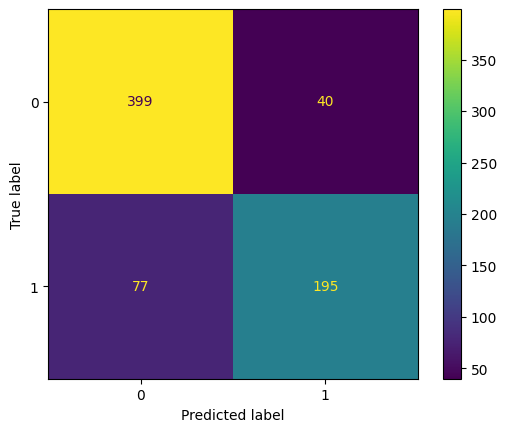

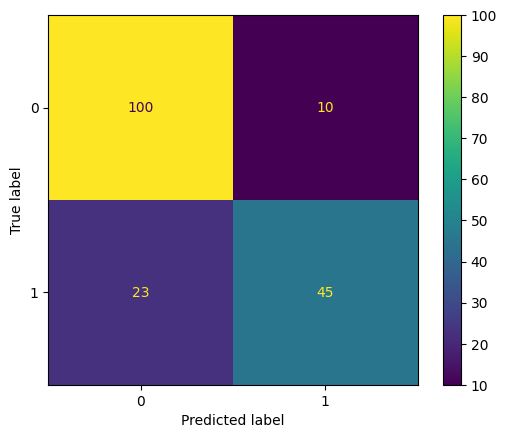

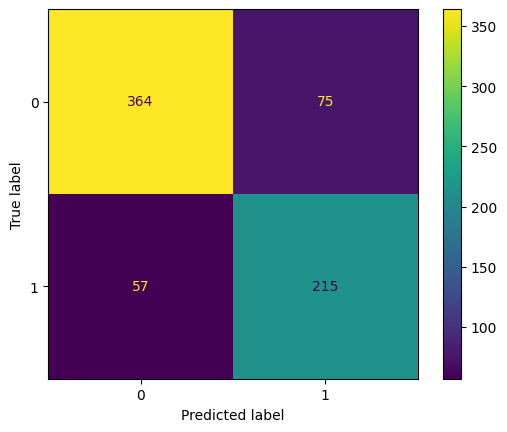

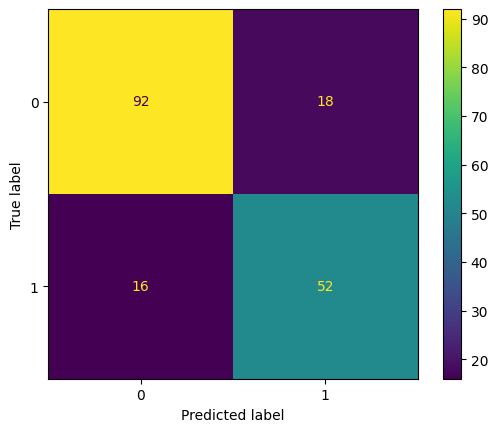

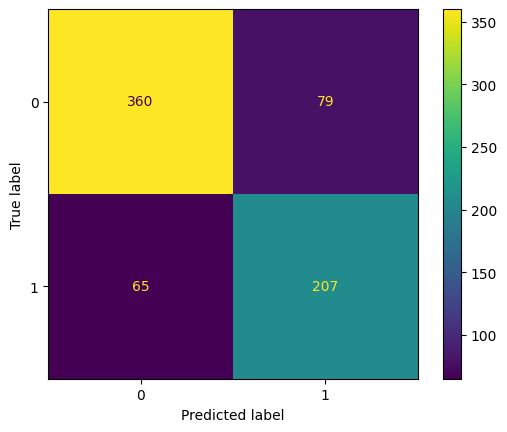

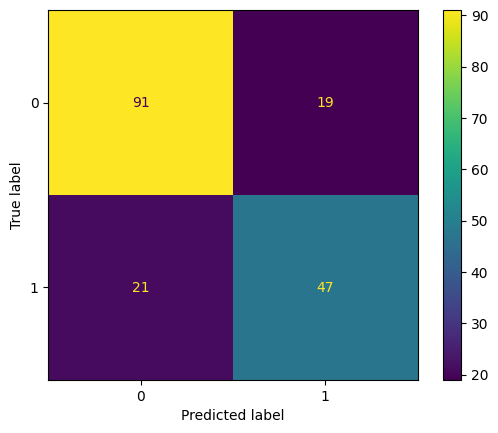

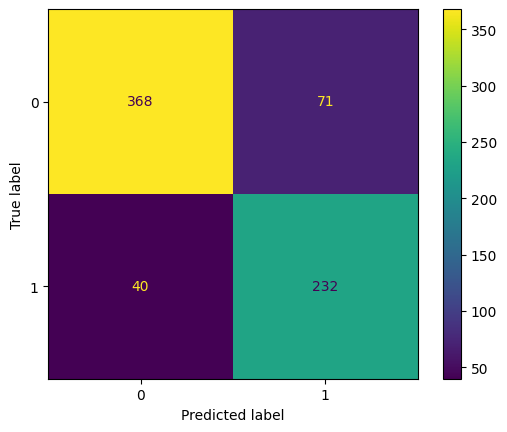

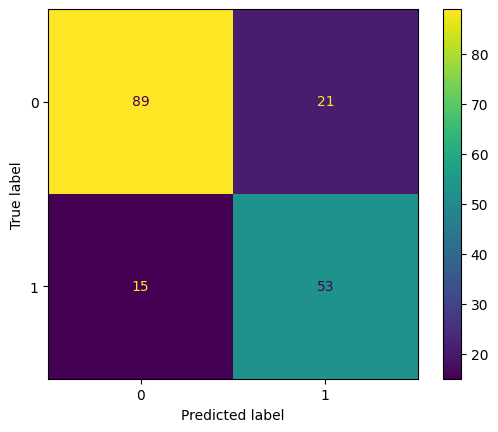

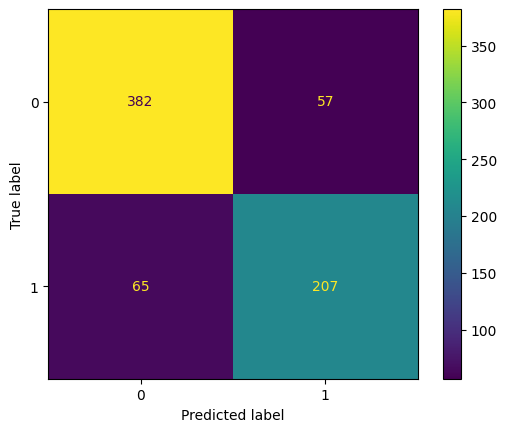

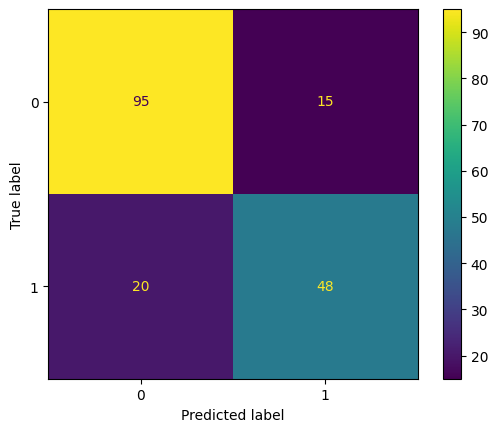

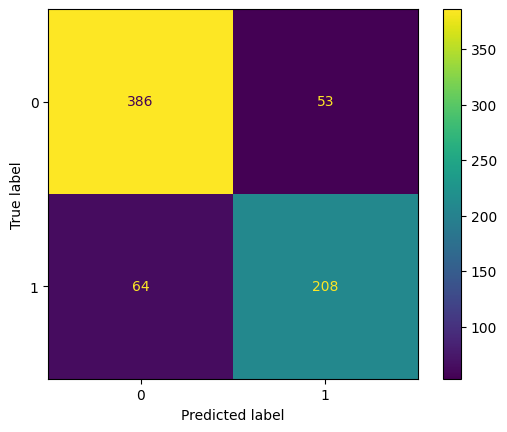

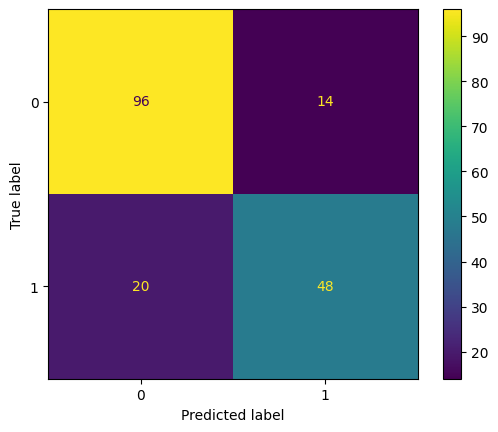

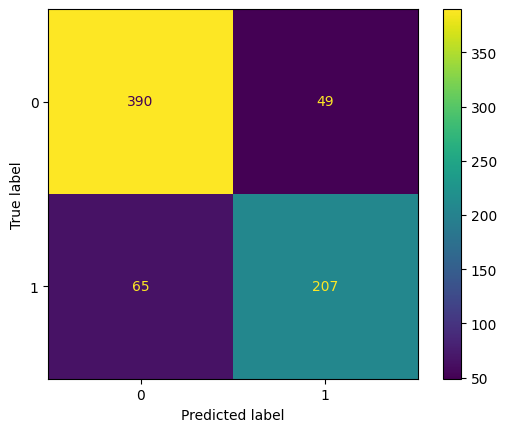

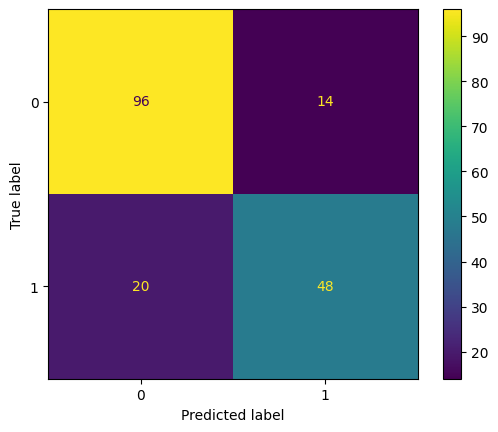

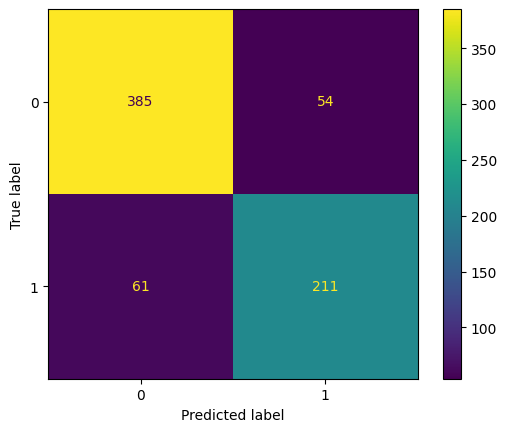

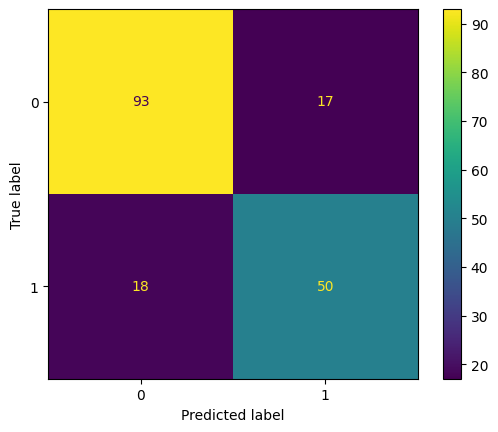

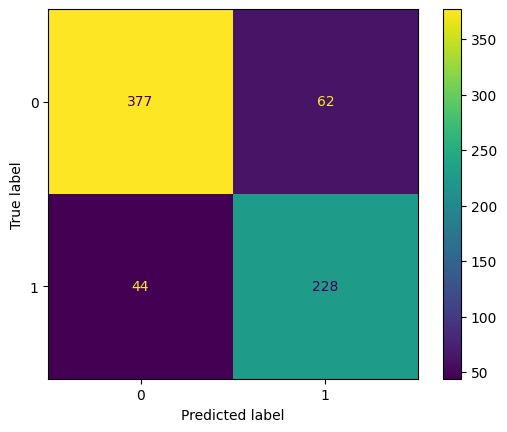

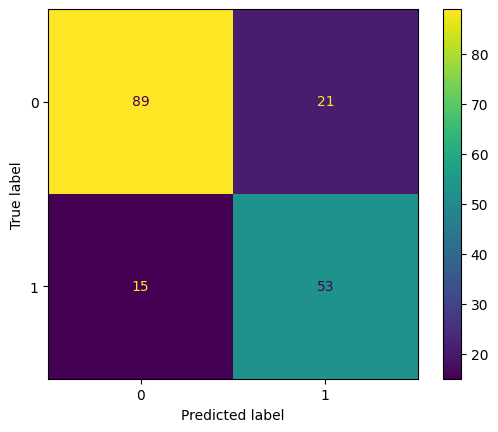

In [ ]:
### ---6. TREINO E AVALIAÇÃO DOS MODELOS--- ###

models = ['KNN', 'logistic_regression', 'linear_SVC', 'rbf_SVC',
          'DT', 'RF', 'GB', 'xgboost', 'lightgbm']

results_list = []

for alg in models:
    print(f"\n==================== {alg} ====================")

    # Treino e avaliação usando treino/validação internos
    best_model, best_params = apply_model(
        alg,
        X_train_final,  # treino interno
        X_val,          # validação interna
        y_train_final,
        y_val
    )

    # Predição na validação interna
    y_pred_val = best_model.predict(X_val)

    # Relatório de métricas
    report = classification_report(y_val, y_pred_val, output_dict=True)

    results_list.append({
        'Model': alg,
        'Accuracy': report['accuracy'],
        'Precision': report['weighted avg']['precision'],
        'Recall': report['weighted avg']['recall'],
        'F1-score': report['weighted avg']['f1-score'],
        'Best Params': best_params
    })

# Consolidar resultados
results_df = pd.DataFrame(results_list)
results_df = results_df.sort_values(by='Accuracy', ascending=False)
results_df.reset_index(drop=True, inplace=True)

print("\n===== Tabela consolidada de métricas =====")
results_df

O nosso objetivo foi não apenas maximizar a accuracy global, mas também assegurar desempenho equilibrado entre as classes, dada a presença de desbalanceamento no dataset original. Por isso, aplicámos técnicas de balanceamento nos modelos que o permitem, como `class_weight='balanced'` ou `scale_pos_weight` no XGBoost, garantindo que a aprendizagem não fosse dominada pela classe majoritária e preservando recall na classe minoritária, fundamental num problema de sobrevivência onde falsos negativos têm impacto significativo.

- XGBoost apresenta o melhor equilíbrio entre treino e teste (accuracy 0.84 treino / 0.80 teste) e recall aceitável da classe minoritária (0.74), sem *overfitting* relevante.

- LightGBM também se comporta bem, com ligeiramente melhor recall na classe minoritária (0.78), mas apresenta uma diferença maior entre treino e teste, indicando algum *overfitting* leve.

- Random Forest e Gradient Boosting (GB) mantêm accuracy global semelhante (0.81 no teste), mas têm recall inferior da classe minoritária (0.71), tornando-os menos robustos para a nossa métrica de interesse.

- KNN, SVM e Decision Tree são mais instáveis, com recall da classe minoritária a variar mais significativamente e sensibilidade maior à escala e ao número limitado de variáveis numéricas.

Em resumo, a nossa escolha recai sobre XGBoost como modelo principal, por combinar robustez, capacidade de lidar com desbalanceamento e performance equilibrada entre classes. LightGBM pode ser considerado uma alternativa, caso pretendamos explorar uma leve melhoria no recall da classe minoritária, sabendo que há um pequeno *trade-off* em *overfitting*.

### **5.2) Aplicação ao df_test**

Agora, por fim, aplicamos o modelo escolhido ao conjunto de teste (`df_test_limpo`) para gerar a submissão para o Kaggle. Como já não temos acesso às labels reais, utilizamos o modelo XGBoost treinado previamente com o treino (X_train, y_train_encoded).

O modelo faz a predição sobre X_test transformado, obtendo os valores de sobrevivência que compõem o CSV de submissão "Kaggle_Titanic_Submission.csv".

In [ ]:
### ---1. MODELO ESCOLHIDO NO TREINO--- ###

# Fit completo com treino completo
final_model = XGBClassifier(**results_df.loc[results_df['Model']=='xgboost', 'Best Params'].values[0],
                            eval_metric='logloss',
                            scale_pos_weight=(sum(y_train_encoded==0)/sum(y_train_encoded==1)))
final_model.fit(X_train, y_train_encoded)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=2, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
### ---2. PREDICT DO TEST--- ###

y_test_pred = final_model.predict(X_test)

In [ ]:
### ---3. CSV DE SUBMISSÃO--- ###

submission = pd.DataFrame({
    'PassengerId': df_test_limpo['PassengerId'],
    'Survived': y_test_pred
})

submission.to_csv('Kaggle_Titanic_Submission.csv', index=False)

Submetemos, então, o ficheiro csv com as previsões do conjunto de teste à competição do Kaggle, utilizando o modelo XGBoost treinado com todos os dados de treino (`df_train_limpo`) e os melhores hiperparâmetros encontrados.

O score obtido na competição foi 0.78229, o que avaliamos como consideravelmente bom, tendo em conta o ranking de todas as submissões. Reconhecemos a dificuldade de atingir scores elevados neste dataset, sobretudo devido à reduzida quantidade de observações disponíveis.

Futuras melhorias poderiam incluir a criação de mais features derivadas dos dados originais, novas tentativas de tratamento da coluna 'Cabin', experimentação com técnicas de *ensemble stacking* ou o uso de algoritmos de regularização mais avançados para mitigar possíveis efeitos de *overfitting* em datasets pequenos.